# Caterpillar Diesel Engine Leak Detection — Exploratory Data Analysis

**Tech Challenge 2026 — Problem Statement 3**

This notebook explores the simulated test-cell dataset for a C13-class diesel engine.
We examine distributions, correlations, and scenario-level sensor behavior to confirm
that intake/exhaust leaks produce detectable signatures in the sensor array.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

DATA_PATH = Path('..') / 'data' / 'caterpillar_testcell_leak_dataset.csv'
OUTPUT_DIR = Path('..') / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

PLOT_DPI = 150

## 1. Load Data & Basic Inspection

In [7]:
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape}')
print(f'\nColumn dtypes:\n{df.dtypes.value_counts()}')
df.head(3)

Shape: (9000, 52)

Column dtypes:
float64    41
object      8
int64       3
Name: count, dtype: int64


,Test_ID,Timestamp,Engine_Serial_No,Test_Cell_ID,Engine_Speed_Setpoint_RPM,Engine_Load_Setpoint_Pct,Test_Mode,Engine_Speed_Actual_RPM,Engine_Load_Actual_Pct,Fuel_Flow_Rate_kgph,...,Compressor_Pressure_Ratio,Turbine_Expansion_Ratio,CAC_Pressure_Drop_kPa,DPF_Delta_Pressure_kPa,Intake_Temp_Rise_Across_CAC_C,Leak_Present,Leak_Location,Leak_Severity,Confidence_Score,Recommended_Action
0,TC2025-RUN01,09:00:00.000,CAT-C13-SN-00412,TC-CELL-03,1800,75,Steady_State,1802.7,74.95,42.272,...,2.1769,2.0314,7.448,3.999,-117.303,0,NaN,NaN,0.970,Continue_Testing
1,TC2025-RUN01,09:00:01.000,CAT-C13-SN-00412,TC-CELL-03,1800,75,Steady_State,1794.3,75.31,41.487,...,2.1663,2.0038,3.206,2.402,-114.241,0,NaN,NaN,0.977,Continue_Testing
2,TC2025-RUN01,09:00:02.000,CAT-C13-SN-00412,TC-CELL-03,1800,75,Steady_State,1799.6,75.38,42.152,...,2.1768,2.0323,7.865,4.180,-116.268,0,NaN,NaN,0.970,Continue_Testing


In [8]:
# Null check
null_counts = df.isnull().sum()
print(f'Total nulls per column (showing non-zero only):')
non_zero = null_counts[null_counts > 0]
if len(non_zero) == 0:
    print('  No missing values found — dataset is complete.')
else:
    print(non_zero)

Total nulls per column (showing non-zero only):
Leak_Location    1800
Leak_Severity    1800
dtype: int64


In [9]:
# Target distribution
print('=== Leak_Location distribution ===')
print(df['Leak_Location'].value_counts())
print('\n=== Leak_Severity distribution ===')
print(df['Leak_Severity'].value_counts())
print('\n=== Recommended_Action distribution ===')
print(df['Recommended_Action'].value_counts())

=== Leak_Location distribution ===
Leak_Location
Intake_PreTurbo         1800
Intake_PostTurbo_CAC    1800
Exhaust_PreTurbine      1800
Exhaust_PostTurbine     1800
Name: count, dtype: int64

=== Leak_Severity distribution ===
Leak_Severity
Moderate    5400
Minor       1800
Name: count, dtype: int64

=== Recommended_Action distribution ===
Recommended_Action
Pause_Test_Inspect_Component    5400
Continue_Testing                1800
Flag_and_Monitor                1800
Name: count, dtype: int64


## 2. Key Sensor Distributions by Leak Scenario

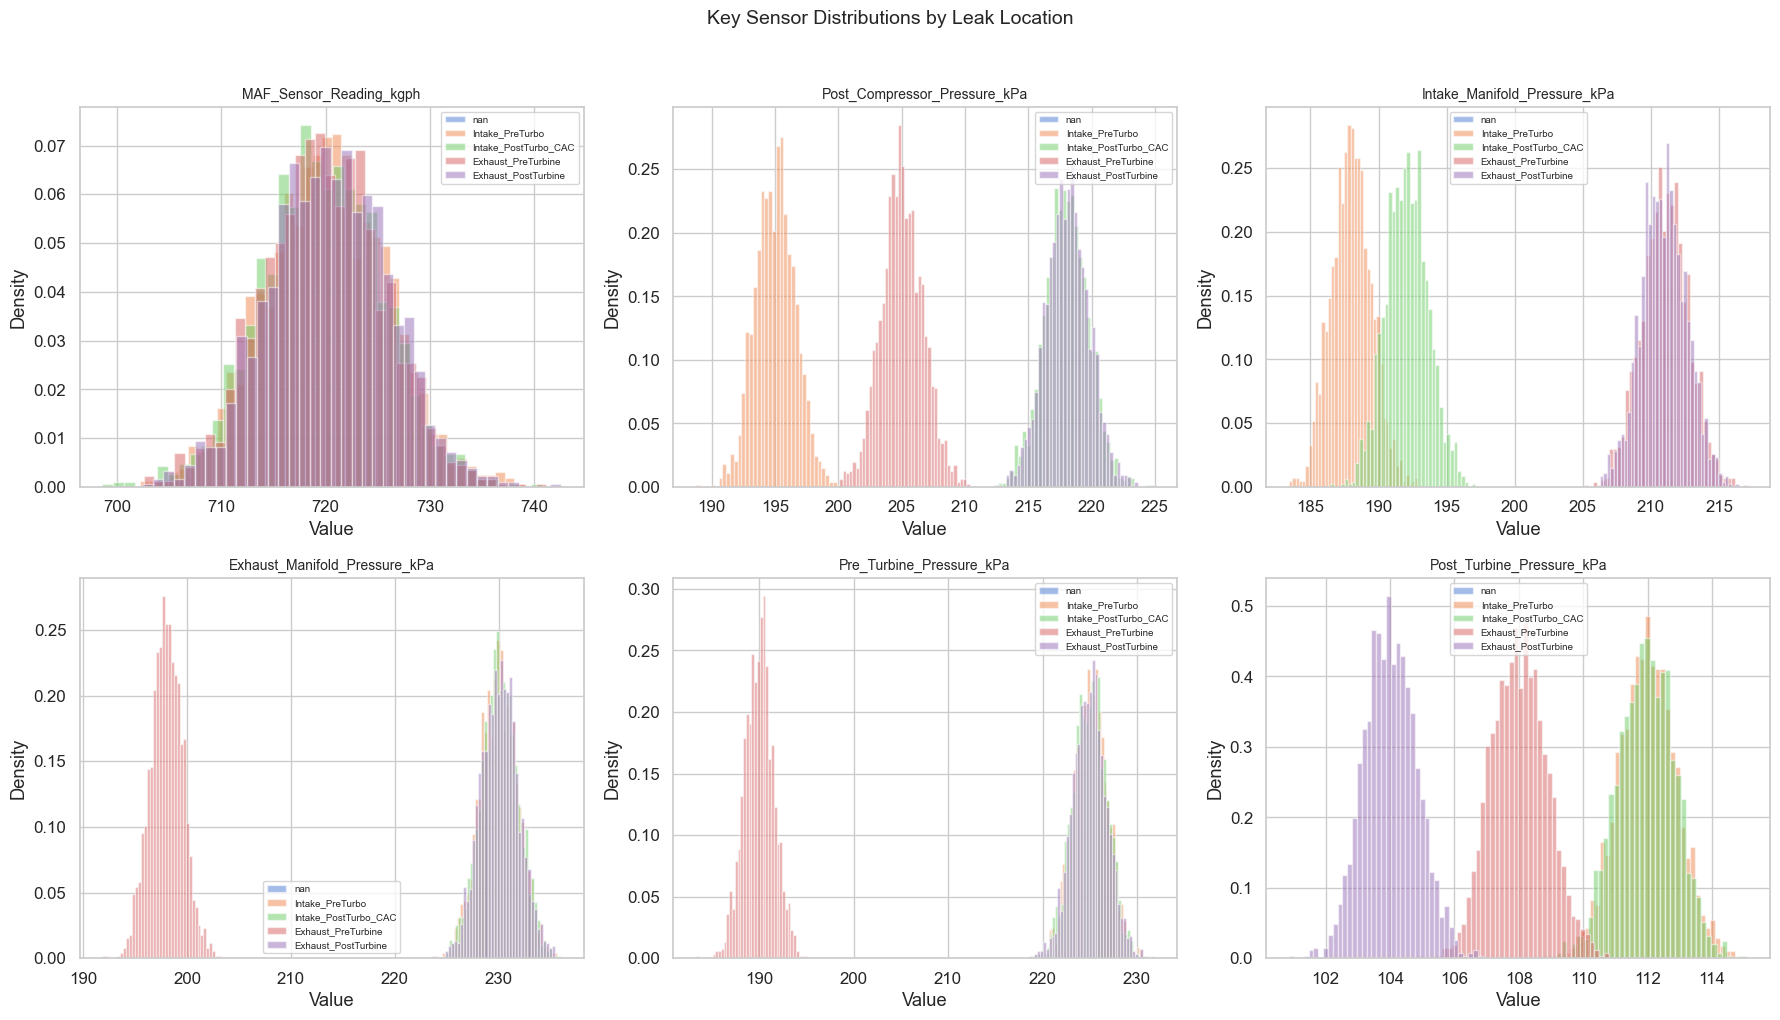

In [10]:
key_sensors = [
    'MAF_Sensor_Reading_kgph',
    'Post_Compressor_Pressure_kPa',
    'Intake_Manifold_Pressure_kPa',
    'Exhaust_Manifold_Pressure_kPa',
    'Pre_Turbine_Pressure_kPa',
    'Post_Turbine_Pressure_kPa',
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flat, key_sensors):
    for loc in df['Leak_Location'].unique():
        subset = df[df['Leak_Location'] == loc]
        ax.hist(subset[col], bins=40, alpha=0.5, label=loc, density=True)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')
    ax.legend(fontsize=7)

fig.suptitle('Key Sensor Distributions by Leak Location', fontsize=14, y=1.02)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'eda_sensor_distributions.png', dpi=PLOT_DPI, bbox_inches='tight')
plt.show()

## 3. Correlation Heatmap — Intake (Group 3) + Exhaust (Group 4) Features

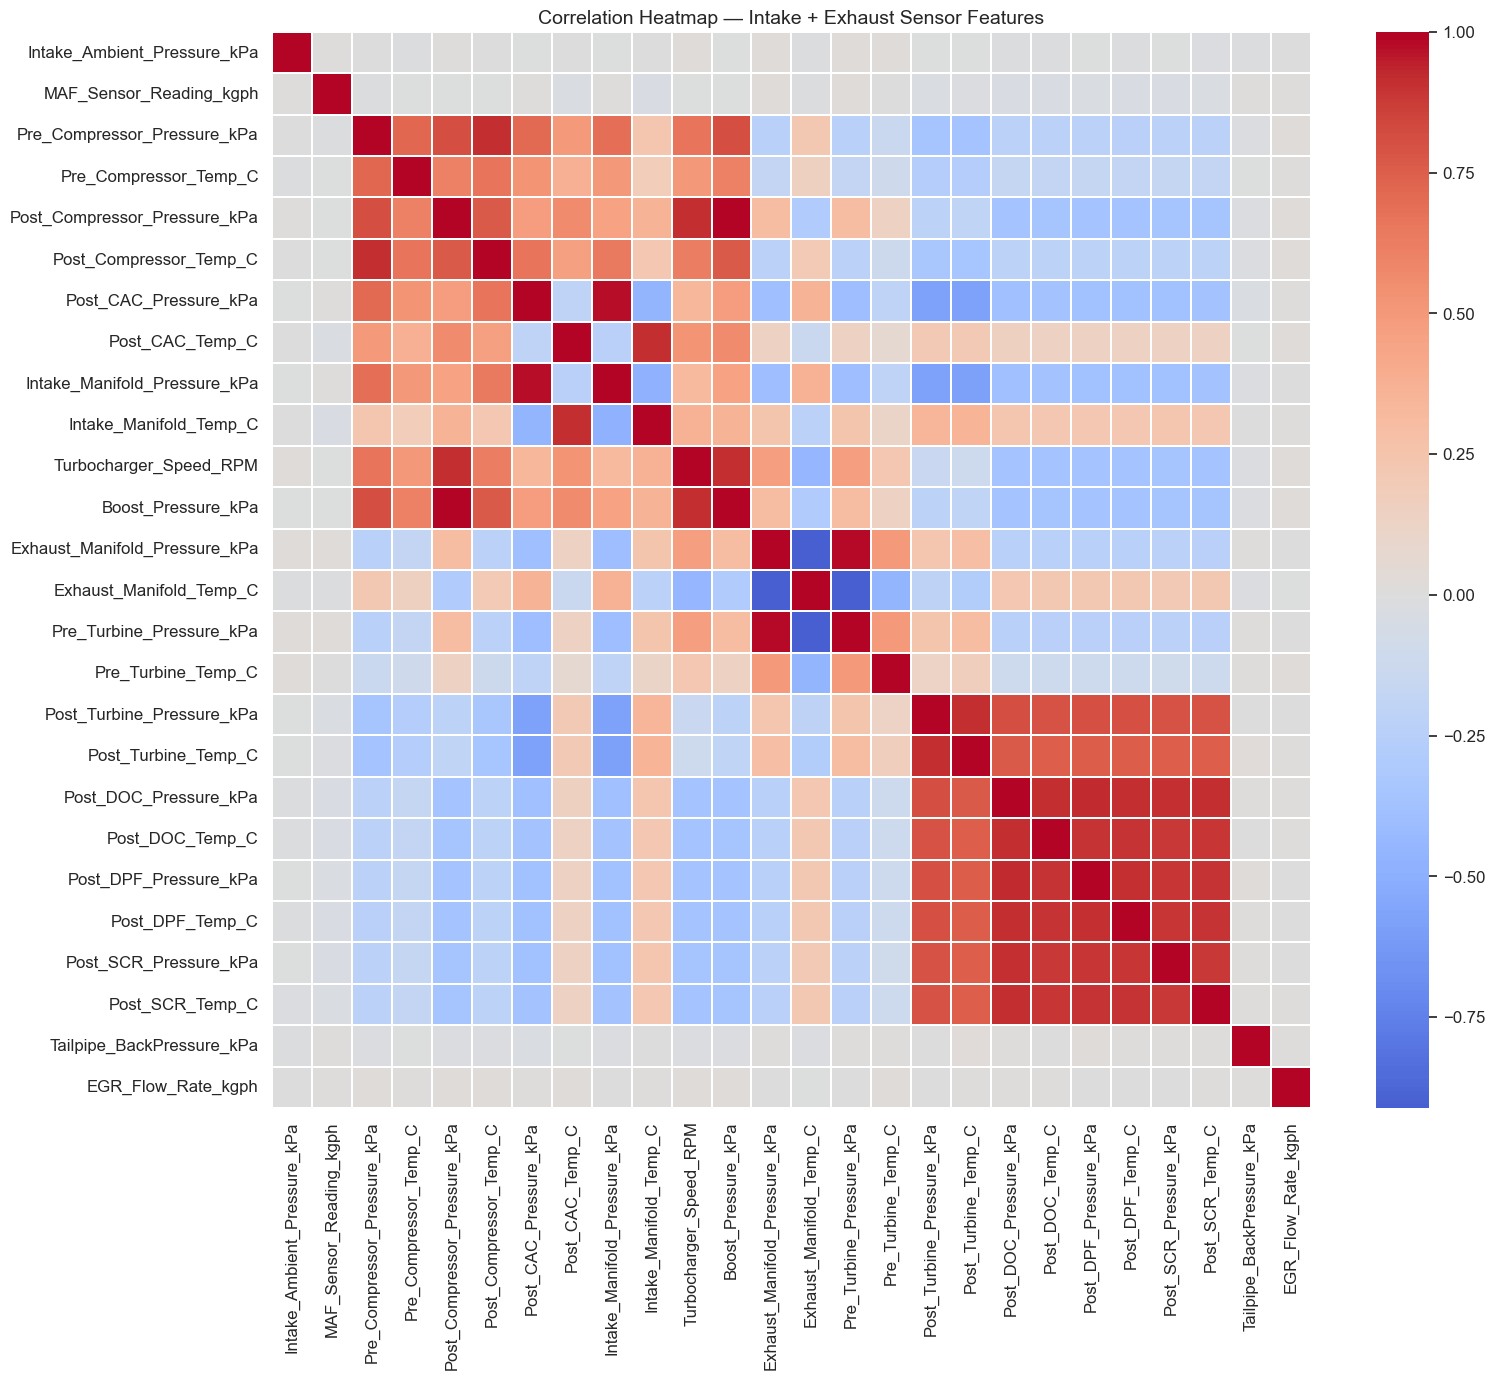

In [11]:
intake_cols = [
    'Intake_Ambient_Pressure_kPa', 'MAF_Sensor_Reading_kgph',
    'Pre_Compressor_Pressure_kPa', 'Pre_Compressor_Temp_C',
    'Post_Compressor_Pressure_kPa', 'Post_Compressor_Temp_C',
    'Post_CAC_Pressure_kPa', 'Post_CAC_Temp_C',
    'Intake_Manifold_Pressure_kPa', 'Intake_Manifold_Temp_C',
    'Turbocharger_Speed_RPM', 'Boost_Pressure_kPa',
]

exhaust_cols = [
    'Exhaust_Manifold_Pressure_kPa', 'Exhaust_Manifold_Temp_C',
    'Pre_Turbine_Pressure_kPa', 'Pre_Turbine_Temp_C',
    'Post_Turbine_Pressure_kPa', 'Post_Turbine_Temp_C',
    'Post_DOC_Pressure_kPa', 'Post_DOC_Temp_C',
    'Post_DPF_Pressure_kPa', 'Post_DPF_Temp_C',
    'Post_SCR_Pressure_kPa', 'Post_SCR_Temp_C',
    'Tailpipe_BackPressure_kPa', 'EGR_Flow_Rate_kgph',
]

corr_cols = intake_cols + exhaust_cols
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(
    corr_matrix, annot=False, cmap='coolwarm', center=0,
    linewidths=0.3, ax=ax,
)
ax.set_title('Correlation Heatmap — Intake + Exhaust Sensor Features', fontsize=14)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'eda_correlation_heatmap.png', dpi=PLOT_DPI, bbox_inches='tight')
plt.show()

## 4. Time-Series Pressure Traces Across All 5 Scenarios

This shows how pressure readings evolve over time for each leak scenario,
visually proving that leaks produce detectable deviations.

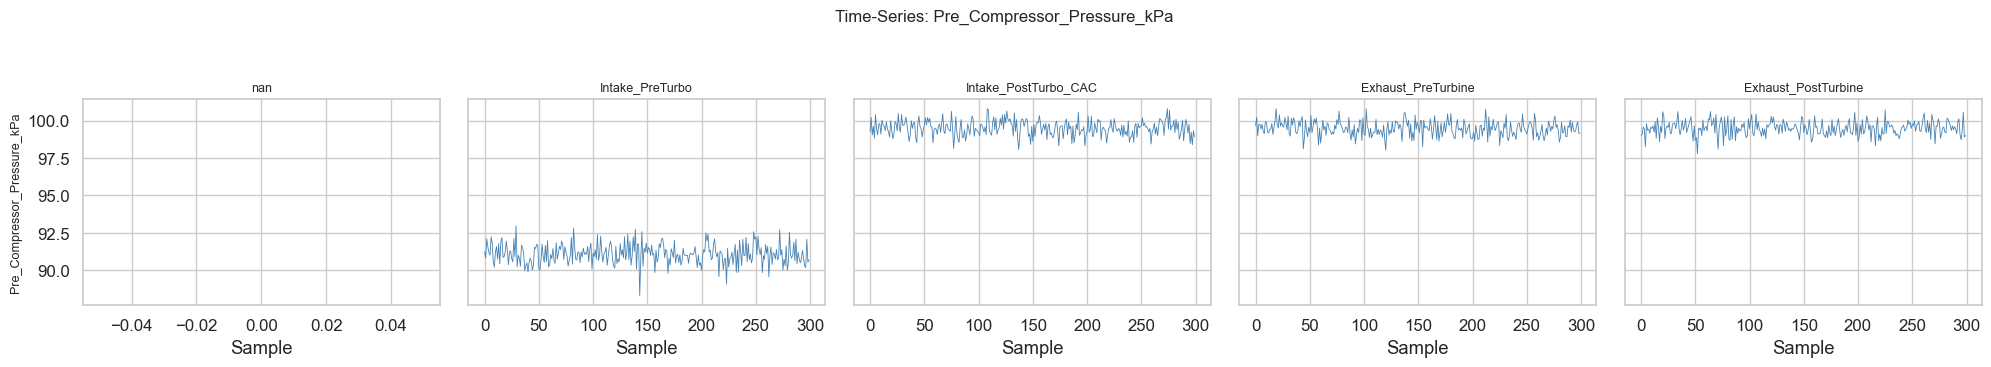

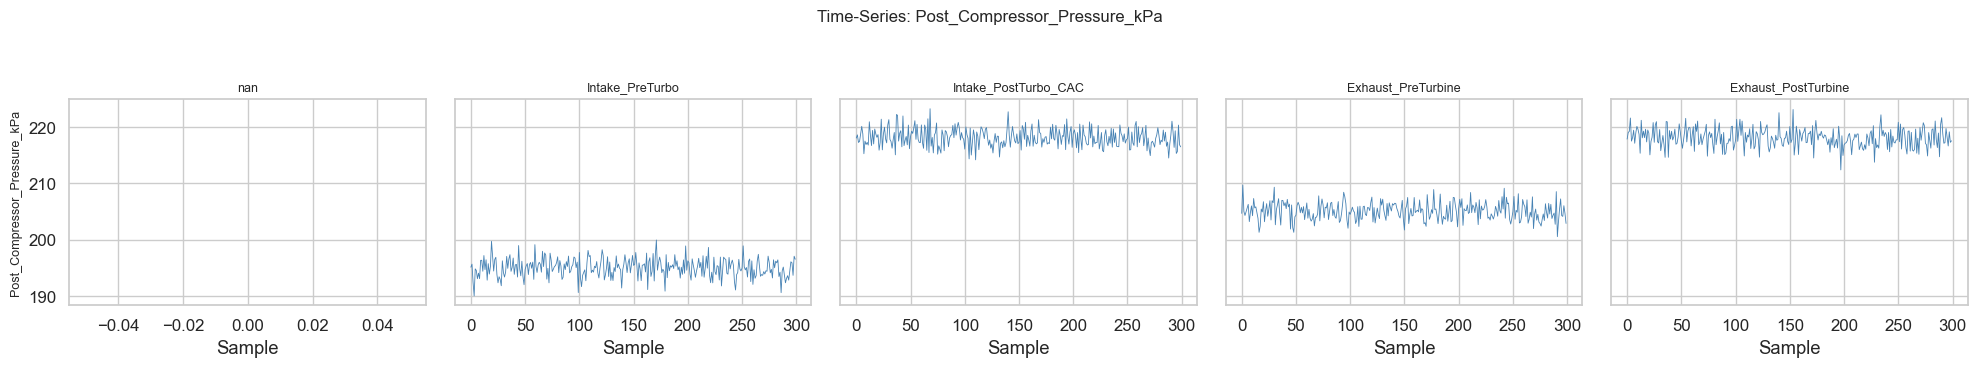

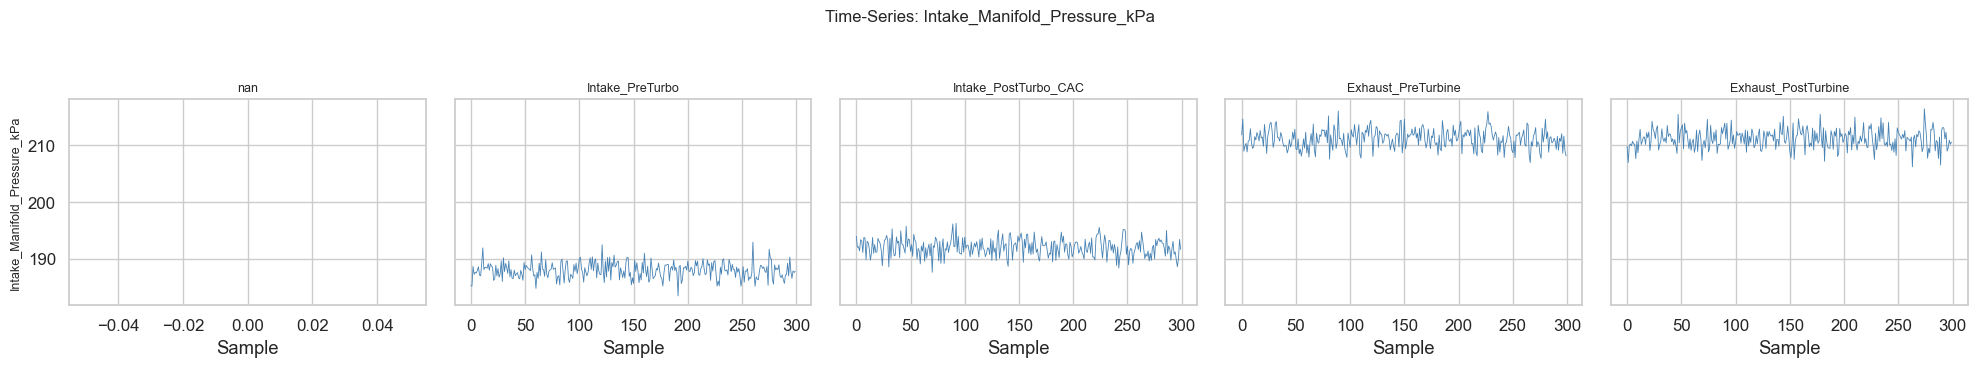

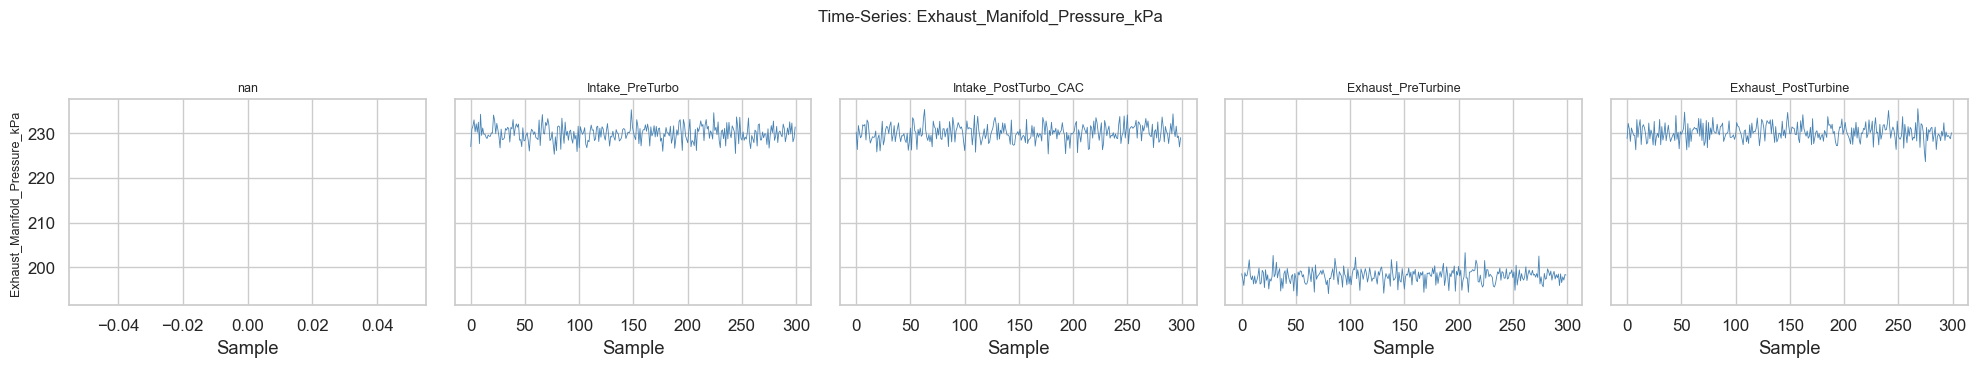

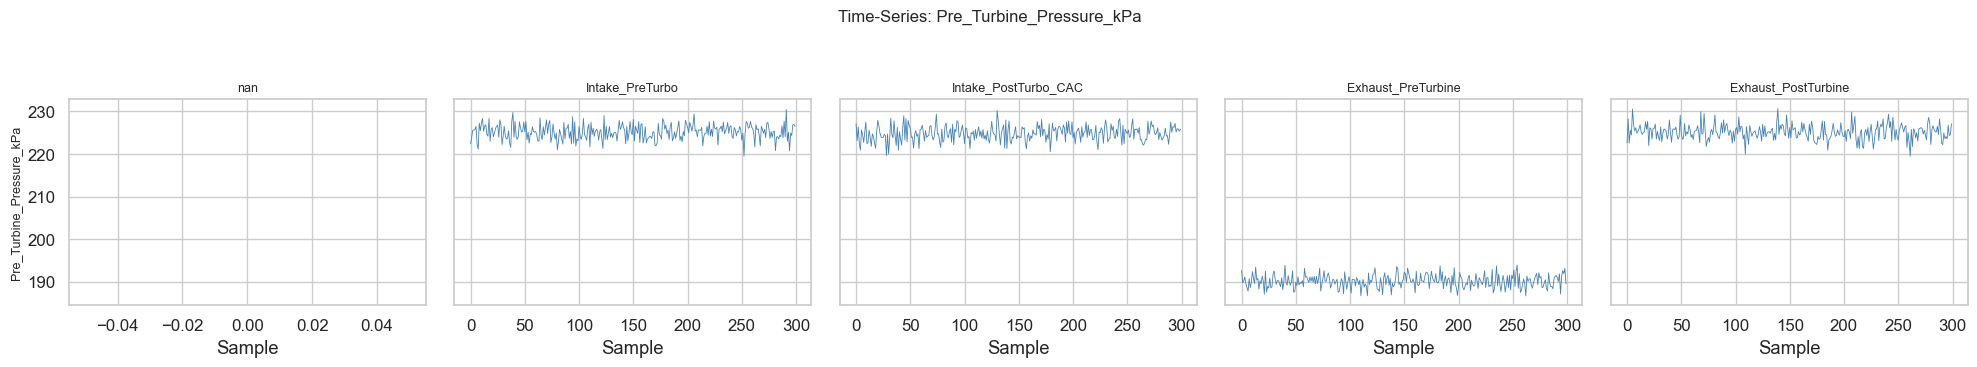

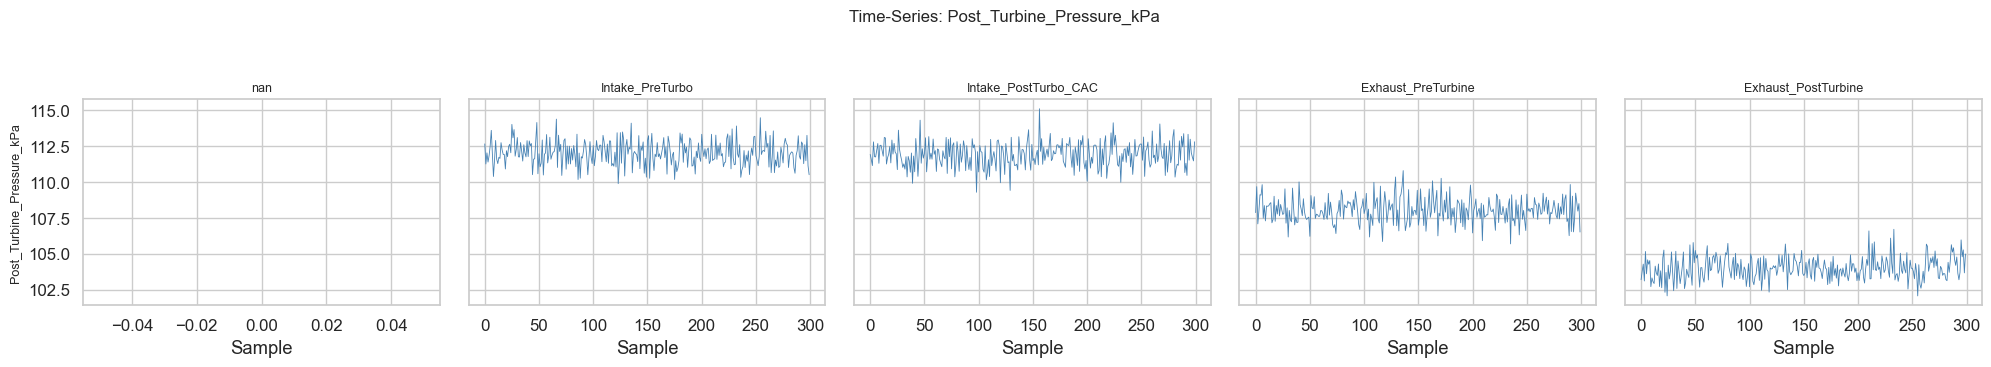

In [12]:
pressure_cols = [
    'Pre_Compressor_Pressure_kPa',
    'Post_Compressor_Pressure_kPa',
    'Intake_Manifold_Pressure_kPa',
    'Exhaust_Manifold_Pressure_kPa',
    'Pre_Turbine_Pressure_kPa',
    'Post_Turbine_Pressure_kPa',
]

scenarios = df['Leak_Location'].unique()

for pcol in pressure_cols:
    fig, axes = plt.subplots(1, len(scenarios), figsize=(20, 3.5), sharey=True)
    for ax, scen in zip(axes, scenarios):
        subset = df[df['Leak_Location'] == scen].reset_index(drop=True)
        # Use first 300 points for clarity
        ax.plot(subset[pcol].values[:300], linewidth=0.6, color='steelblue')
        ax.set_title(scen, fontsize=9)
        ax.set_xlabel('Sample')
    axes[0].set_ylabel(pcol, fontsize=9)
    fig.suptitle(f'Time-Series: {pcol}', fontsize=12, y=1.05)
    plt.tight_layout()
    fname = pcol.replace(' ', '_').lower()
    fig.savefig(OUTPUT_DIR / f'eda_ts_{fname}.png', dpi=PLOT_DPI, bbox_inches='tight')
    plt.show()

## 5. Boxplots — Most Discriminative Features by Leak Location

`Compressor_Pressure_Ratio` and `Turbine_Expansion_Ratio` are the most
physics-informed features for separating leak scenarios.

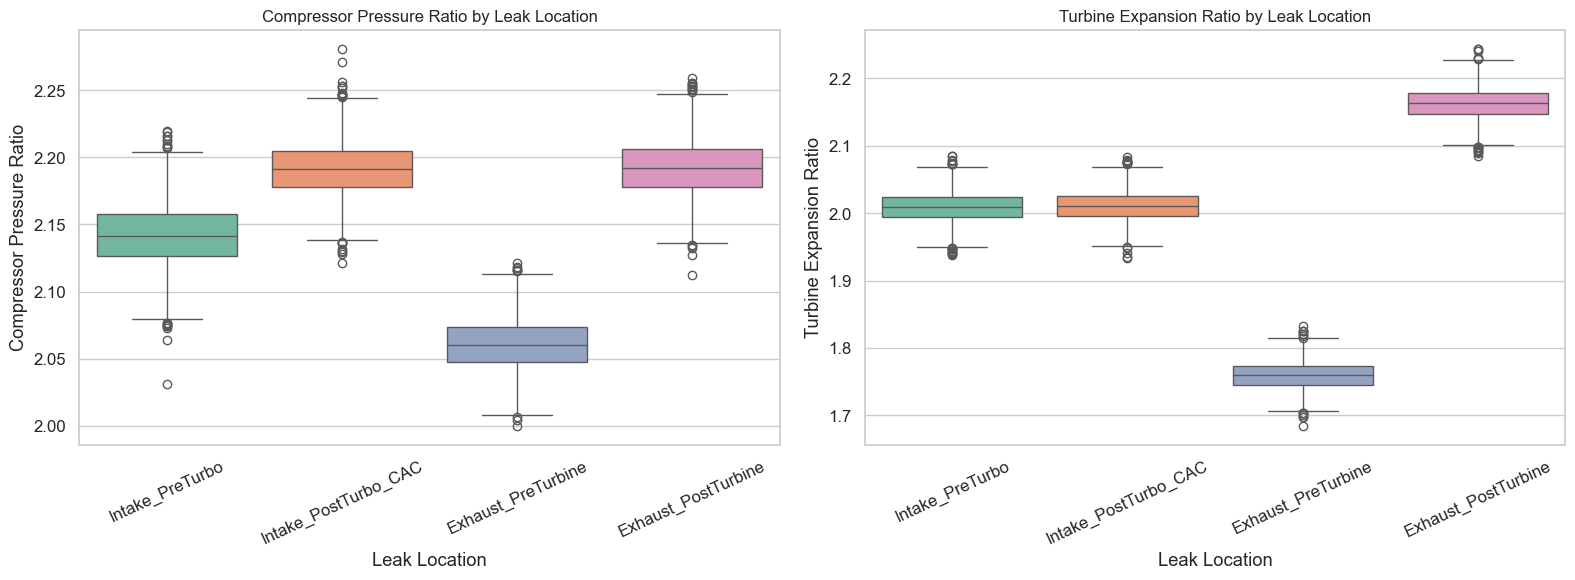

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(
    data=df, x='Leak_Location', y='Compressor_Pressure_Ratio',
    ax=axes[0], palette='Set2',
)
axes[0].set_title('Compressor Pressure Ratio by Leak Location', fontsize=12)
axes[0].tick_params(axis='x', rotation=25)
axes[0].set_xlabel('Leak Location')
axes[0].set_ylabel('Compressor Pressure Ratio')

sns.boxplot(
    data=df, x='Leak_Location', y='Turbine_Expansion_Ratio',
    ax=axes[1], palette='Set2',
)
axes[1].set_title('Turbine Expansion Ratio by Leak Location', fontsize=12)
axes[1].tick_params(axis='x', rotation=25)
axes[1].set_xlabel('Leak Location')
axes[1].set_ylabel('Turbine Expansion Ratio')

plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'eda_discriminative_boxplots.png', dpi=PLOT_DPI, bbox_inches='tight')
plt.show()

## 6. Summary Statistics

In [14]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
summary = df[numeric_cols].describe().T
summary['skew'] = df[numeric_cols].skew()
summary['kurtosis'] = df[numeric_cols].kurtosis()
summary.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Engine_Speed_Setpoint_RPM,9000.0,1800.000,0.000,1800.000,1800.000,1800.000,1800.000,1800.000,0.000,0.000
Engine_Load_Setpoint_Pct,9000.0,75.000,0.000,75.000,75.000,75.000,75.000,75.000,0.000,0.000
Engine_Speed_Actual_RPM,9000.0,1800.082,5.386,1781.200,1796.500,1800.200,1803.800,1819.500,-0.037,-0.002
Engine_Load_Actual_Pct,9000.0,74.996,0.381,73.470,74.740,75.000,75.252,76.320,-0.038,-0.043
Fuel_Flow_Rate_kgph,9000.0,42.010,0.418,40.353,41.727,42.014,42.292,43.422,-0.013,-0.042
Engine_Coolant_Temp_C,9000.0,87.993,0.439,86.040,87.700,87.990,88.290,89.970,-0.014,0.091
Engine_Oil_Pressure_bar,9000.0,4.199,0.042,4.047,4.171,4.199,4.227,4.350,-0.009,0.032
Ambient_Temp_C,9000.0,31.999,0.316,30.840,31.780,32.000,32.210,33.160,-0.020,-0.017
Ambient_Pressure_kPa,9000.0,101.300,0.204,100.516,101.160,101.301,101.440,102.032,0.003,-0.065
Ambient_Humidity_Pct,9000.0,67.981,1.355,63.000,67.070,67.970,68.900,73.110,-0.012,0.052


## Key Observations

1. **No missing values** — the dataset is clean and simulation-complete.
2. **Balanced scenarios** — 1800 rows per leak location (5 scenarios × 1800 = 9000).
3. **Pressure features show clear separation** between normal and leak scenarios in the time-series plots.
4. **Compressor_Pressure_Ratio** and **Turbine_Expansion_Ratio** are the strongest discriminators — boxplots show well-separated medians across leak types.
5. **Intake vs. Exhaust leaks** affect different sensor groups, confirming the physical model: intake leaks depress post-compressor pressure, exhaust leaks reduce pre-turbine pressure.
6. The correlation heatmap reveals sensor clusters (intake path, exhaust path) that align with physical subsystems — useful for feature engineering and model interpretation.